In [886]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [887]:
df = pd.read_csv("Bengaluru_House_Data.csv")
df.sample(10)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
7484,Built-up Area,Ready To Move,Vijay Nagar,6 Bedroom,NaN,2300,7.0,0.0,160.00
5335,Built-up Area,Ready To Move,6th block Koramangala,2 BHK,Krone S,1117,2.0,1.0,110.00
1109,Super built-up Area,Ready To Move,Electronic City,2 BHK,Itelaa,880,2.0,2.0,29.00
5970,Plot Area,Ready To Move,Mysore Road,1 Bedroom,NaN,45,1.0,0.0,23.00
7166,Super built-up Area,Ready To Move,Tata Nagar,3 BHK,NaN,1750,3.0,3.0,75.00
9121,Super built-up Area,Ready To Move,Varthur,2 BHK,Hirio L,1091,2.0,1.0,33.82
11791,Super built-up Area,Ready To Move,GM Palaya,1 BHK,Srg Bnc,675,1.0,1.0,35.00
3276,Super built-up Area,21-Jun,Vijayanagar,3 BHK,Saityat,1520,2.0,1.0,103.00
10477,Plot Area,Ready To Move,Whitefield,5 Bedroom,NaN,1500,6.0,3.0,155.00
8342,Super built-up Area,Ready To Move,Kacharakanahalli,3 BHK,JPoldGo,1400,3.0,3.0,69.00


In [888]:
df.shape

(13320, 9)

In [889]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


- Availibility

In [890]:
df['availability'].nunique()

81

In [891]:
df[df['availability']=='Ready To Move']

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.0
5,Super built-up Area,Ready To Move,Whitefield,2 BHK,DuenaTa,1170,2.0,1.0,38.0
...,...,...,...,...,...,...,...,...,...
13314,Super built-up Area,Ready To Move,Green Glen Layout,3 BHK,SoosePr,1715,3.0,3.0,112.0
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0


In [892]:
df['availability'].unique()

<StringArray>
[              '19-Dec',        'Ready To Move',               '18-May',
               '18-Feb',               '18-Nov',               '20-Dec',
               '17-Oct',               '21-Dec',               '19-Sep',
               '20-Sep',               '18-Mar',               '20-Feb',
               '18-Apr',               '20-Aug',               '18-Oct',
               '19-Mar',               '17-Sep',               '18-Dec',
               '17-Aug',               '19-Apr',               '18-Jun',
               '22-Dec',               '22-Jan',               '18-Aug',
               '19-Jan',               '17-Jul',               '18-Jul',
               '21-Jun',               '20-May',               '19-Aug',
               '18-Sep',               '17-May',               '17-Jun',
               '21-May',               '18-Jan',               '20-Mar',
               '17-Dec',               '16-Mar',               '19-Jun',
               '22-Jun',             

In [893]:
df['availability'] = df['availability'].apply(lambda x:1 if x=='Ready To Move' else 0).astype(int)



df['availability'] 

0        0
1        1
2        1
3        1
4        1
        ..
13315    1
13316    1
13317    1
13318    0
13319    1
Name: availability, Length: 13320, dtype: int64

  - total_sqft is in str (change into int)  
  - balcony is in flaot (change into int)

In [894]:
df.describe()

,availability,bath,balcony,price
count,13320.000000,13247.000000,12711.000000,13320.000000
mean,0.794369,2.692610,1.584376,112.565627
std,0.404177,1.341458,0.817263,148.971674
min,0.000000,1.000000,0.000000,8.000000
25%,1.000000,2.000000,1.000000,50.000000
50%,1.000000,2.000000,2.000000,72.000000
75%,1.000000,3.000000,2.000000,120.000000
max,1.000000,40.000000,3.000000,3600.000000


In [895]:
df.describe(include=object)

C:\Users\theha\AppData\Local\Temp\ipykernel_2204\3998025828.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=object)


,area_type,location,size,society,total_sqft
count,13320,13319,13304,7818,13320
unique,4,1305,31,2688,2117
top,Super built-up Area,Whitefield,2 BHK,GrrvaGr,1200
freq,8790,540,5199,80,843


- in bath max is 40 (maybe outlier)

In [896]:
df.duplicated().sum()

np.int64(618)

In [897]:
df[df.duplicated()]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
242,Super built-up Area,0,Chandapura,1 BHK,SunceEs,645,1.0,1.0,16.45
887,Super built-up Area,0,Chandapura,2 BHK,SunceEs,1015,2.0,2.0,25.88
905,Super built-up Area,0,Kanakpura Road,1 BHK,PrarePa,525,1.0,1.0,26.00
971,Super built-up Area,1,Haralur Road,3 BHK,NRowse,1464,3.0,2.0,56.00
1115,Super built-up Area,1,Haralur Road,2 BHK,NaN,1027,2.0,2.0,44.00
...,...,...,...,...,...,...,...,...,...
13285,Super built-up Area,1,VHBCS Layout,2 BHK,OlarkLa,1353,2.0,2.0,110.00
13299,Super built-up Area,0,Whitefield,4 BHK,Prtates,2830 - 2882,5.0,0.0,154.50
13311,Plot Area,1,Ramamurthy Nagar,7 Bedroom,NaN,1500,9.0,2.0,250.00
13313,Super built-up Area,1,Uttarahalli,3 BHK,Aklia R,1345,2.0,1.0,57.00


In [898]:
df= df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [899]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5314
total_sqft         0
bath              72
balcony          604
price              0
dtype: int64

- Society

In [900]:
df.drop('society', axis=1, inplace =True )

### Size

In [901]:
df['size'].sample(10)

2695         2 BHK
5589         1 BHK
11085        2 BHK
12052    1 Bedroom
10561        3 BHK
5198         2 BHK
10905        3 BHK
2480         3 BHK
3726     3 Bedroom
10683        2 BHK
Name: size, dtype: str

- merging bedroom and BHK into total counts of bedrooms.

In [902]:
df['bedrooms'] = df['size'].str.split(' ').str[0]
df['bedrooms']


0        2
1        4
2        3
3        3
4        2
        ..
13314    3
13315    5
13316    4
13317    2
13318    4
Name: bedrooms, Length: 12702, dtype: object

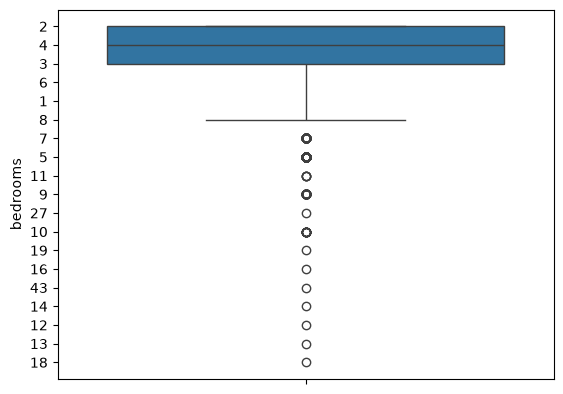

In [903]:
sns.boxplot(y=df['bedrooms'])
plt.show()

In [904]:
df['bedrooms'] = pd.to_numeric(df['bedrooms'],errors ='coerce')

In [905]:
df[df['bedrooms']>=20][['size','total_sqft', 'bath','bedrooms','price']]

,size,total_sqft,bath,bedrooms,price
1718,27 BHK,8000,27.0,27.0,230.0
4684,43 Bedroom,2400,40.0,43.0,660.0


In [906]:
df[df['bedrooms']>=10][['size','total_sqft', 'bath','bedrooms','price']]

,size,total_sqft,bath,bedrooms,price
459,11 BHK,5000,9.0,11.0,360.0
1718,27 BHK,8000,27.0,27.0,230.0
1735,10 Bedroom,750,10.0,10.0,90.0
1768,11 Bedroom,1200,11.0,11.0,170.0
1795,10 Bedroom,1660,10.0,10.0,475.0
3096,10 BHK,12000,12.0,10.0,525.0
3379,19 BHK,2000,16.0,19.0,490.0
3523,10 Bedroom,1200,10.0,10.0,105.0
3609,16 BHK,10000,16.0,16.0,550.0
3853,11 Bedroom,1200,6.0,11.0,150.0


In [907]:
df = df[df['bedrooms'] < 20]

In [908]:
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())
df['bedrooms'] = df['bedrooms'].astype(int)
df['bedrooms']

0        2
1        4
2        3
3        3
4        2
        ..
13314    3
13315    5
13316    4
13317    2
13318    4
Name: bedrooms, Length: 12684, dtype: int64

In [909]:

df.isnull().sum()

area_type         0
availability      0
location          1
size              0
total_sqft        0
bath             56
balcony         588
price             0
bedrooms          0
dtype: int64

- Bath

In [910]:
df['bath'].unique()

array([ 2.,  5.,  3.,  4.,  6.,  1.,  9., nan,  8.,  7., 11., 10., 14.,
       12., 16., 15., 13., 18.])

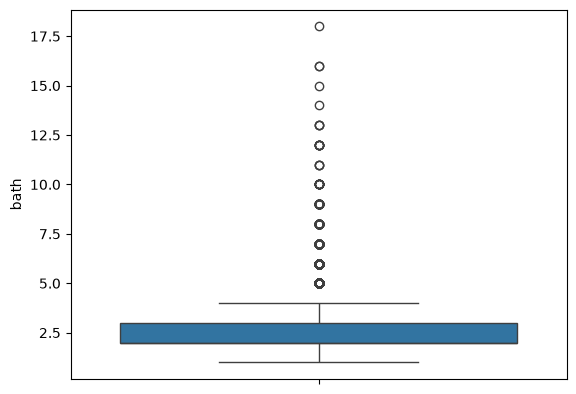

In [911]:
sns.boxplot(y = df['bath'])
plt.show()

In [912]:
df.loc[df["bath"].isna()]

,area_type,availability,location,size,total_sqft,bath,balcony,price,bedrooms
56,Built-up Area,0,Devanahalli,4 Bedroom,3010 - 3410,NaN,NaN,192.000,4
81,Built-up Area,0,Hennur Road,4 Bedroom,2957 - 3450,NaN,NaN,224.500,4
224,Super built-up Area,0,Devanahalli,3 BHK,1520 - 1740,NaN,NaN,74.820,3
344,Super built-up Area,0,Kanakpura Road,1 BHK,525,NaN,NaN,21.530,1
669,Super built-up Area,0,JP Nagar,5 BHK,4400 - 6640,NaN,NaN,375.000,5
702,Super built-up Area,0,JP Nagar,5 BHK,4400 - 6800,NaN,NaN,548.500,5
801,Super built-up Area,0,JP Nagar,4 BHK,4000 - 5249,NaN,NaN,453.000,4
941,Super built-up Area,1,Whitefield,4 Bedroom,3606 - 5091,NaN,NaN,304.000,4
1264,Built-up Area,0,Hennur,3 Bedroom,2264,NaN,NaN,155.000,3
1267,Super built-up Area,0,Yelahanka,3 BHK,1440 - 1884,NaN,NaN,67.980,3


In [913]:
df['bath'] = df['bath'].fillna(
    df['bath'].median()
)

df['bath'] = df['bath'].astype(int)

In [914]:
df[df['bath'] > 10][
    ['size', 'bedrooms', 'bath', 'total_sqft', 'price']
]

,size,bedrooms,bath,total_sqft,price
938,9 Bedroom,9,11,1260,290.0
1078,9 Bedroom,9,14,3300,500.0
1768,11 Bedroom,11,11,1200,170.0
1953,8 Bedroom,8,12,1200,110.0
1979,8 Bedroom,8,12,990,120.0
3096,10 BHK,10,12,12000,525.0
3379,19 BHK,19,16,2000,490.0
3609,16 BHK,16,16,10000,550.0
4916,14 BHK,14,15,1250,125.0
6937,9 Bedroom,9,12,2600,675.0


In [915]:
df['bath']

0        2
1        5
2        2
3        3
4        2
        ..
13314    3
13315    4
13316    5
13317    2
13318    4
Name: bath, Length: 12684, dtype: int64

- balcony

In [916]:
df['balcony'].unique()

array([ 1.,  3., nan,  2.,  0.])

In [917]:
df['balcony'].value_counts()

balcony
2.0    4824
1.0    4640
3.0    1625
0.0    1007
Name: count, dtype: int64

In [918]:
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

df['balcony'] = df['balcony'].astype(int)

In [919]:
df.isnull().sum()

area_type       0
availability    0
location        1
size            0
total_sqft      0
bath            0
balcony         0
price           0
bedrooms        0
dtype: int64

- Location

In [920]:
df['location'].unique()

<StringArray>
[                       'Electronic City Phase II',
                                'Chikka Tirupathi',
                                     'Uttarahalli',
                              'Lingadheeranahalli',
                                        'Kothanur',
                                      'Whitefield',
                                'Old Airport Road',
                                    'Rajaji Nagar',
                                    'Marathahalli',
                                    'Gandhi Bazar',
 ...
                               'Masjid e Alkareem',
                                   'Sindhi Colony',
                             'Kanakapur main road',
                       'Prasanna layout Herohalli',
                               'Sarvobhogam Nagar',
                                  'Pattegarhpalya',
                                     'Tilak Nagar',
 '12th cross srinivas nagar banshankari 3rd stage',
                               'Havanur exten

In [921]:
df.dropna(subset=['location'], inplace=True)
df['location'].isna().sum()

np.int64(0)

In [922]:
df['location'].nunique()

1303

In [923]:
df.isna().sum()

area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
bedrooms        0
dtype: int64

In [924]:
df.describe()

,availability,bath,balcony,price,bedrooms
count,12683.000000,12683.000000,12683.000000,12683.000000,12683.000000
mean,0.801782,2.703146,1.603485,114.627615,2.815659
std,0.398673,1.299781,0.808941,151.852804,1.247012
min,0.000000,1.000000,0.000000,8.000000,1.000000
25%,1.000000,2.000000,1.000000,50.000000,2.000000
50%,1.000000,2.000000,2.000000,73.000000,3.000000
75%,1.000000,3.000000,2.000000,122.000000,3.000000
max,1.000000,18.000000,3.000000,3600.000000,19.000000


- Total Square fit

In [925]:

df['total_sqft'].unique()

<StringArray>
[       '1056',        '2600',        '1440',        '1521',        '1200',
        '1170',        '2732',        '3300',        '1310',        '1020',
 ...
        '3124',        '9200',         '613',         '250',        '2395',
 '1020 - 1130',        '2758', '1133 - 1384',         '774',        '4689']
Length: 2110, dtype: str

- Ranges ARE present (1020-1130,1133-1384,etc.)

In [926]:
import re

def convert_sqft(x):
    x = str(x).strip()

    # Example: 1020-1130
    if '-' in x:
        try:
            a, b = x.split('-')
            return (float(a) + float(b)) / 2
        except:
            return np.nan

    # Example: 1056sqft, 32.46ft
    match = re.search(r'\d+(?:\.\d+)?', x)

    if match:
        return float(match.group())

    return np.nan

In [927]:


df['total_sqft'] = df['total_sqft'].apply(convert_sqft)

In [928]:
df['total_sqft']

0        1056.0
1        2600.0
2        1440.0
3        1521.0
4        1200.0
          ...  
13314    1715.0
13315    3453.0
13316    3600.0
13317    1141.0
13318    4689.0
Name: total_sqft, Length: 12683, dtype: float64

In [929]:
df['total_sqft'].isna().sum()

np.int64(0)

In [930]:
df.drop(columns=['size'],inplace=True)


In [931]:
df

,area_type,availability,location,total_sqft,bath,balcony,price,bedrooms
0,Super built-up Area,0,Electronic City Phase II,1056.0,2,1,39.07,2
1,Plot Area,1,Chikka Tirupathi,2600.0,5,3,120.00,4
2,Built-up Area,1,Uttarahalli,1440.0,2,3,62.00,3
3,Super built-up Area,1,Lingadheeranahalli,1521.0,3,1,95.00,3
4,Super built-up Area,1,Kothanur,1200.0,2,1,51.00,2
...,...,...,...,...,...,...,...,...
13314,Super built-up Area,1,Green Glen Layout,1715.0,3,3,112.00,3
13315,Built-up Area,1,Whitefield,3453.0,4,0,231.00,5
13316,Super built-up Area,1,Richards Town,3600.0,5,2,400.00,4
13317,Built-up Area,1,Raja Rajeshwari Nagar,1141.0,2,1,60.00,2


In [932]:
df.info()

<class 'pandas.DataFrame'>
Index: 12683 entries, 0 to 13318
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     12683 non-null  str    
 1   availability  12683 non-null  int64  
 2   location      12683 non-null  str    
 3   total_sqft    12683 non-null  float64
 4   bath          12683 non-null  int64  
 5   balcony       12683 non-null  int64  
 6   price         12683 non-null  float64
 7   bedrooms      12683 non-null  int64  
dtypes: float64(2), int64(4), str(2)
memory usage: 891.8 KB


In [933]:
df['location'].value_counts()

location
Whitefield                                         514
Sarjapur  Road                                     369
Electronic City                                    286
Kanakpura Road                                     237
Thanisandra                                        229
                                                  ... 
Pattegarhpalya                                       1
Tilak Nagar                                          1
12th cross srinivas nagar banshankari 3rd stage      1
Havanur extension                                    1
Abshot Layout                                        1
Name: count, Length: 1303, dtype: int64

In [934]:
df.drop('location',axis =1,inplace=True)

In [935]:
df = pd.get_dummies(
    df,
    columns=['area_type'],
    drop_first=True,
    dtype=int
)

In [936]:
df.shape

(12683, 9)

In [937]:
df.dtypes

availability                        int64
total_sqft                        float64
bath                                int64
balcony                             int64
price                             float64
bedrooms                            int64
area_type_Carpet  Area              int64
area_type_Plot  Area                int64
area_type_Super built-up  Area      int64
dtype: object

## Linear Regression

In [938]:
df.head()

,availability,total_sqft,bath,balcony,price,bedrooms,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area
0,0,1056.0,2,1,39.07,2,0,0,1
1,1,2600.0,5,3,120.00,4,0,1,0
2,1,1440.0,2,3,62.00,3,0,0,0
3,1,1521.0,3,1,95.00,3,0,0,1
4,1,1200.0,2,1,51.00,2,0,0,1


In [939]:
X = df.drop('price', axis=1)

y = df['price']

- Train-test

In [940]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

- Create model

In [941]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

- Train

In [942]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-1.71, 0.06,33.57,..., 9.75,67.56, 0.62]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['availability','total_sqft','bath',...,'area_type_Carpet Area', 'area_type_Plot Area','area_type_Super built-up Area']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-49.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


- Prediction

In [943]:
y_pred = model.predict(X_test)

- EVALUATION

In [944]:
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 44.91448225087796
MSE: 14382.71496541641
RMSE: 119.927957396999
R2 Score: 0.41222660229826236


- ACTUAL VS PREDICTED GRAPH

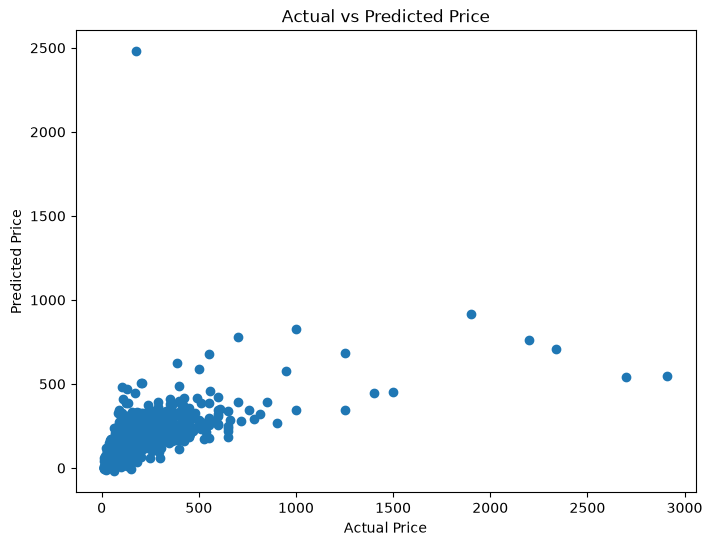

In [945]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted Price")

plt.show()

- COEFFICIENTS AND INTERCEPT

In [946]:
print("Intercept:", model.intercept_)

print("Coefficients:")

print(model.coef_)

Intercept: -49.904546400628746
Coefficients:
[-1.71358266e+00  5.57100030e-02  3.35702675e+01  2.68053240e+00
 -9.67648872e+00  9.75411006e+00  6.75551294e+01  6.23178382e-01]
